# 3. Blending, provider value, and what happens when feeds fail

Uses the predictions from notebook 2. Blend weights are fit only on the validation half-year (Jul-Dec 2025); everything is scored on 2026.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from src import wind

DATA = "../data/wind"
FIG = "figures"
os.makedirs(FIG, exist_ok=True)
if not os.path.exists(f"{DATA}/wind_hourly.parquet"):
    raise SystemExit("Run the download first, from the repo root: EIA_API_KEY=... python -m src.wind_data")

INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})
pd.set_option("display.width", 160)

In [2]:
t = pd.read_parquet(f"{DATA}/wind_hourly.parquet")
P = pd.read_parquet(f"{DATA}/preds_hub.parquet")             # written by notebook 2
y = t["wind_mw"]
START = "2024-03-07"                                           # common start of all three providers
cap = wind.reference_capacity(y, START)

**Do providers make the same mistakes?** Error correlation near 1 means they miss together, and blending them adds little.

In [3]:
weights, results, corr = wind.blend_results(P, y, "d1", cap)
corr.round(2)

,GFS,ICON,ECMWF
GFS,1.00,0.49,0.53
ICON,0.49,1.00,0.62
ECMWF,0.53,0.62,1.00


In [4]:
weights.round(3)

,equal,inverse_MSE,constrained
GFS,0.333,0.318,0.366
ICON,0.333,0.365,0.401
ECMWF,0.333,0.316,0.232


In [5]:
results.round(1)

,MAE_MW,nMAE_%,bias_MW,vs_best_MW,CI_low,CI_high,clearly_better
best single (ICON),2003.614501,7.65422,-328.489195,0.0,0.0,0.0,False
equal blend,1705.294034,6.514574,-363.124582,-298.320467,-359.674648,-235.756712,True
inverse-MSE blend,1705.139499,6.513984,-361.32119,-298.475001,-357.510785,-238.723992,True
constrained blend,1710.906799,6.536016,-350.33299,-292.707701,-351.65179,-234.273279,True
equal blend + bias fix,1698.409107,6.488272,53.605747,-305.205394,-389.731388,-221.620099,True
best single (ICON) + bias fix,2003.526157,7.653882,56.196915,-0.088344,-45.450721,46.316055,False


- **The equal blend beats the best single provider by about 300 MW (15%)**, and the bootstrap interval is well clear of zero.
- **Fitted weights don't beat equal weights.** With three similar providers and half a year of validation data, there's nothing to gain from estimating weights, and some risk.
- **The recent-bias fix** removes the negative bias (−363 to about +54 MW) but barely moves MAE. The bias is real, but small relative to day-to-day error.

**What does each provider add?** Remove it from the equal blend and measure the loss:

In [6]:
wind.drop_one(P, y, "d1").round(1)

,MAE_change_MW,CI_low,CI_high,clearly_adds_value
GFS,97.937297,60.646936,135.999228,True
ICON,91.847695,58.089352,128.770416,True
ECMWF,69.566099,36.556898,99.622069,True


Every provider clearly earns its place: dropping any one costs 70-100 MW. **Day 2:**

In [7]:
_, results2, corr2 = wind.blend_results(P, y, "d2", cap)
results2.round(1)

,MAE_MW,nMAE_%,bias_MW,vs_best_MW,CI_low,CI_high,clearly_better
best single (ICON),2215.558824,8.463891,-534.711082,0.0,0.0,0.0,False
equal blend,1903.32958,7.271111,-415.309682,-312.229244,-387.423198,-232.211259,True
inverse-MSE blend,1901.614756,7.26456,-420.343808,-313.944068,-387.117154,-235.846807,True
constrained blend,1903.926143,7.27339,-413.705466,-311.632681,-384.020898,-234.196551,True
equal blend + bias fix,1894.701573,7.23815,59.738718,-320.857251,-422.1392,-218.374255,True
best single (ICON) + bias fix,2213.239556,8.455031,59.494328,-2.319267,-59.971675,59.613347,False


In [8]:
wind.drop_one(P, y, "d2").round(1)

,MAE_change_MW,CI_low,CI_high,clearly_adds_value
GFS,83.720997,41.718232,127.297392,True
ICON,117.045896,77.904434,156.774933,True
ECMWF,86.742219,56.030715,117.402716,True


The day-2 blend (7.27% nMAE) beats the best *day-1* single provider (7.65%): blending is worth more than a day of lead time. **Fallbacks:** what gets delivered as feeds fail?

In [9]:
chain = wind.fallback_chain(P, y, "d1", cap, START)
chain.round(1)

,MAE_MW,nMAE_%
all providers,1705.3,6.5
GFS down: blend of the rest,1803.2,6.9
ICON down: blend of the rest,1797.1,6.9
ECMWF down: blend of the rest,1774.9,6.8
only ICON left,2003.6,7.7
only GFS left,2067.4,7.9
every feed down: climatology,5315.8,20.3


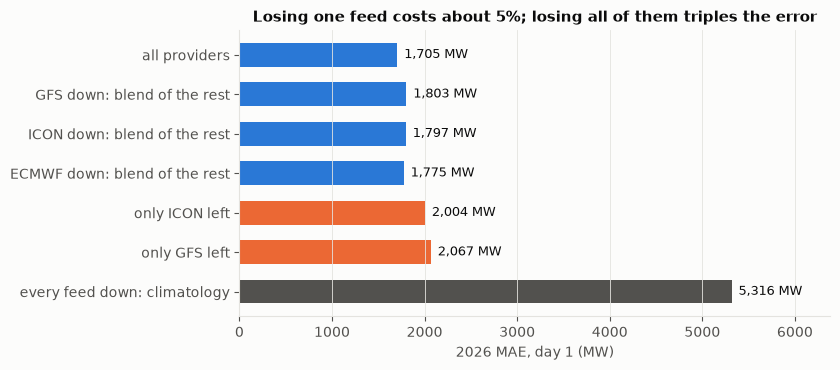

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
colors = [BLUE] + [BLUE] * 3 + [ORANGE] * 2 + [INK2]
ax.barh(chain.index, chain["MAE_MW"], color=colors[:len(chain)], height=0.6)
for i, v in enumerate(chain["MAE_MW"]):
    ax.annotate(f"{v:,.0f} MW", (v, i), xytext=(5, 0), textcoords="offset points", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, chain["MAE_MW"].max() * 1.2)
ax.set_xlabel("2026 MAE, day 1 (MW)")
ax.grid(axis="y", visible=False)
ax.set_title("Losing one feed costs about 5%; losing all of them triples the error")
fig.tight_layout()
fig.savefig(f"{FIG}/fallback_chain.png", dpi=150)
plt.show()

**Recommendation:** keep all three providers in an equal blend; none is redundant, and each adds 70-120 MW. If one feed fails, blend the other two (about +5% error). If all fail, fall back to climatology rather than deliver nothing, but treat that as an emergency: it triples the error.